# A história dos PPAs de Santa Catarina, 2004-2027

Seis planos plurianuais, vinte anos, **529 programas**. Este notebook conta, em sequência, o que os planos dizem e o que fazem: primeiro no plano inteiro, depois nos **42 programas de política industrial**. Recupera a narrativa da primeira versão (palavras de cada PPA, evolução dos termos, similaridade entre planos), agora com todos os programas. Cada capítulo traz uma figura e a leitura; os testes completos estão em `analise_ppa_inteiro.ipynb` e `redes_ppa.ipynb`.

**A história em cinco frases**

1. **O agro sai de cena.** É o único tema que muda de forma significativa no plano inteiro: 2,3% dos lemas em 2004-2007, 0,4% em 2024-2027.
2. **A inovação chega com a política industrial** em 2008-2011, ocupa o centro dela até 2019 e depois se espalha para a modernização do Estado.
3. **No último plano, a política industrial troca inovação por competitividade**, emprego e economia.
4. **O discurso sobe, o dinheiro desce:** a parcela da política industrial no orçamento e o crédito a empresas encolhem a cada plano.
5. **Planos copiados, política reescrita:** em 2024-2027 o plano repete três quartos do texto anterior, mas a política industrial é reescrita junto com novas secretarias.

Medida: contagem e % dos lemas (substantivos, verbos e adjetivos de objetivo + justificativa). Afirmação que não sai dos documentos: [verificar].

In [1]:
# No Google Colab: baixa o repositório com os resultados. No computador local, não faz nada.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tcc"):
        !git clone -q https://github.com/andreydeps/tcc-politica-industrial-sc.git /content/tcc
    %cd /content/tcc

In [2]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
S = RAIZ / "saidas"
sys.path.insert(0, str(RAIZ / "scripts"))
from ppa_inteiro_analise import carregar, PER
from historia import palavras_caracteristicas, temas_no_tempo, agro, quem_fala_de_inovacao, discurso_orcamento, copia

p, s, f = carregar()

def fig(nome, largura=950):
    display(Image(filename=str(S / nome), width=largura))

def tabela(df, casas=1, p_cols=("p variação", "p tendência")):
    num = lambda k: (lambda v: "" if pd.isna(v) else f"{v:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", "."))
    fmt = {c: num(0 if pd.api.types.is_integer_dtype(df[c]) else 3 if c in p_cols else casas)
           for c in df.select_dtypes("number").columns}
    display(df.style.hide(axis="index").format(fmt))

## 0. Os planos

In [3]:
tabela(p.groupby("periodo").agg(**{"programas no PPA (todos entram na análise)": ("codigo", "size"),
                                   "dos quais de política industrial": ("selecionado", "sum"),
                                   "lemas (todos os programas)": ("n_lemas", "sum")})
       .reset_index().rename(columns={"periodo": "PPA"}), 0)

PPA,programas no PPA (todos entram na análise),dos quais de política industrial,lemas (todos os programas)
2004-2007,118,9,2.989
2008-2011,65,4,1.750
2012-2015,85,8,2.566
2016-2019,87,7,2.623
2020-2023,88,7,2.965
2024-2027,86,7,2.792


A base é o **plano inteiro: 529 programas**. A coluna do meio só indica quantos deles são de política industrial (os 42 selecionados), que aparecem ao lado do plano inteiro quando a comparação interessa. O 2004-2007 tem mais programas, e mais fragmentados; o 2008-2011 tem menos texto (1.750 lemas). Por isso as comparações são sempre em % do próprio PPA.

## 1. Do que cada plano fala

Palavras **características** de cada PPA: quantas vezes a palavra é mais frequente naquele PPA do que nos outros (contagem; mínimo de 5 ocorrências no plano inteiro e 3 na política industrial). Ao lado, o **TF-IDF com 20 palavras**, como na primeira versão.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_palavras_ppa_inteiro.png


figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_palavras_selecionados.png


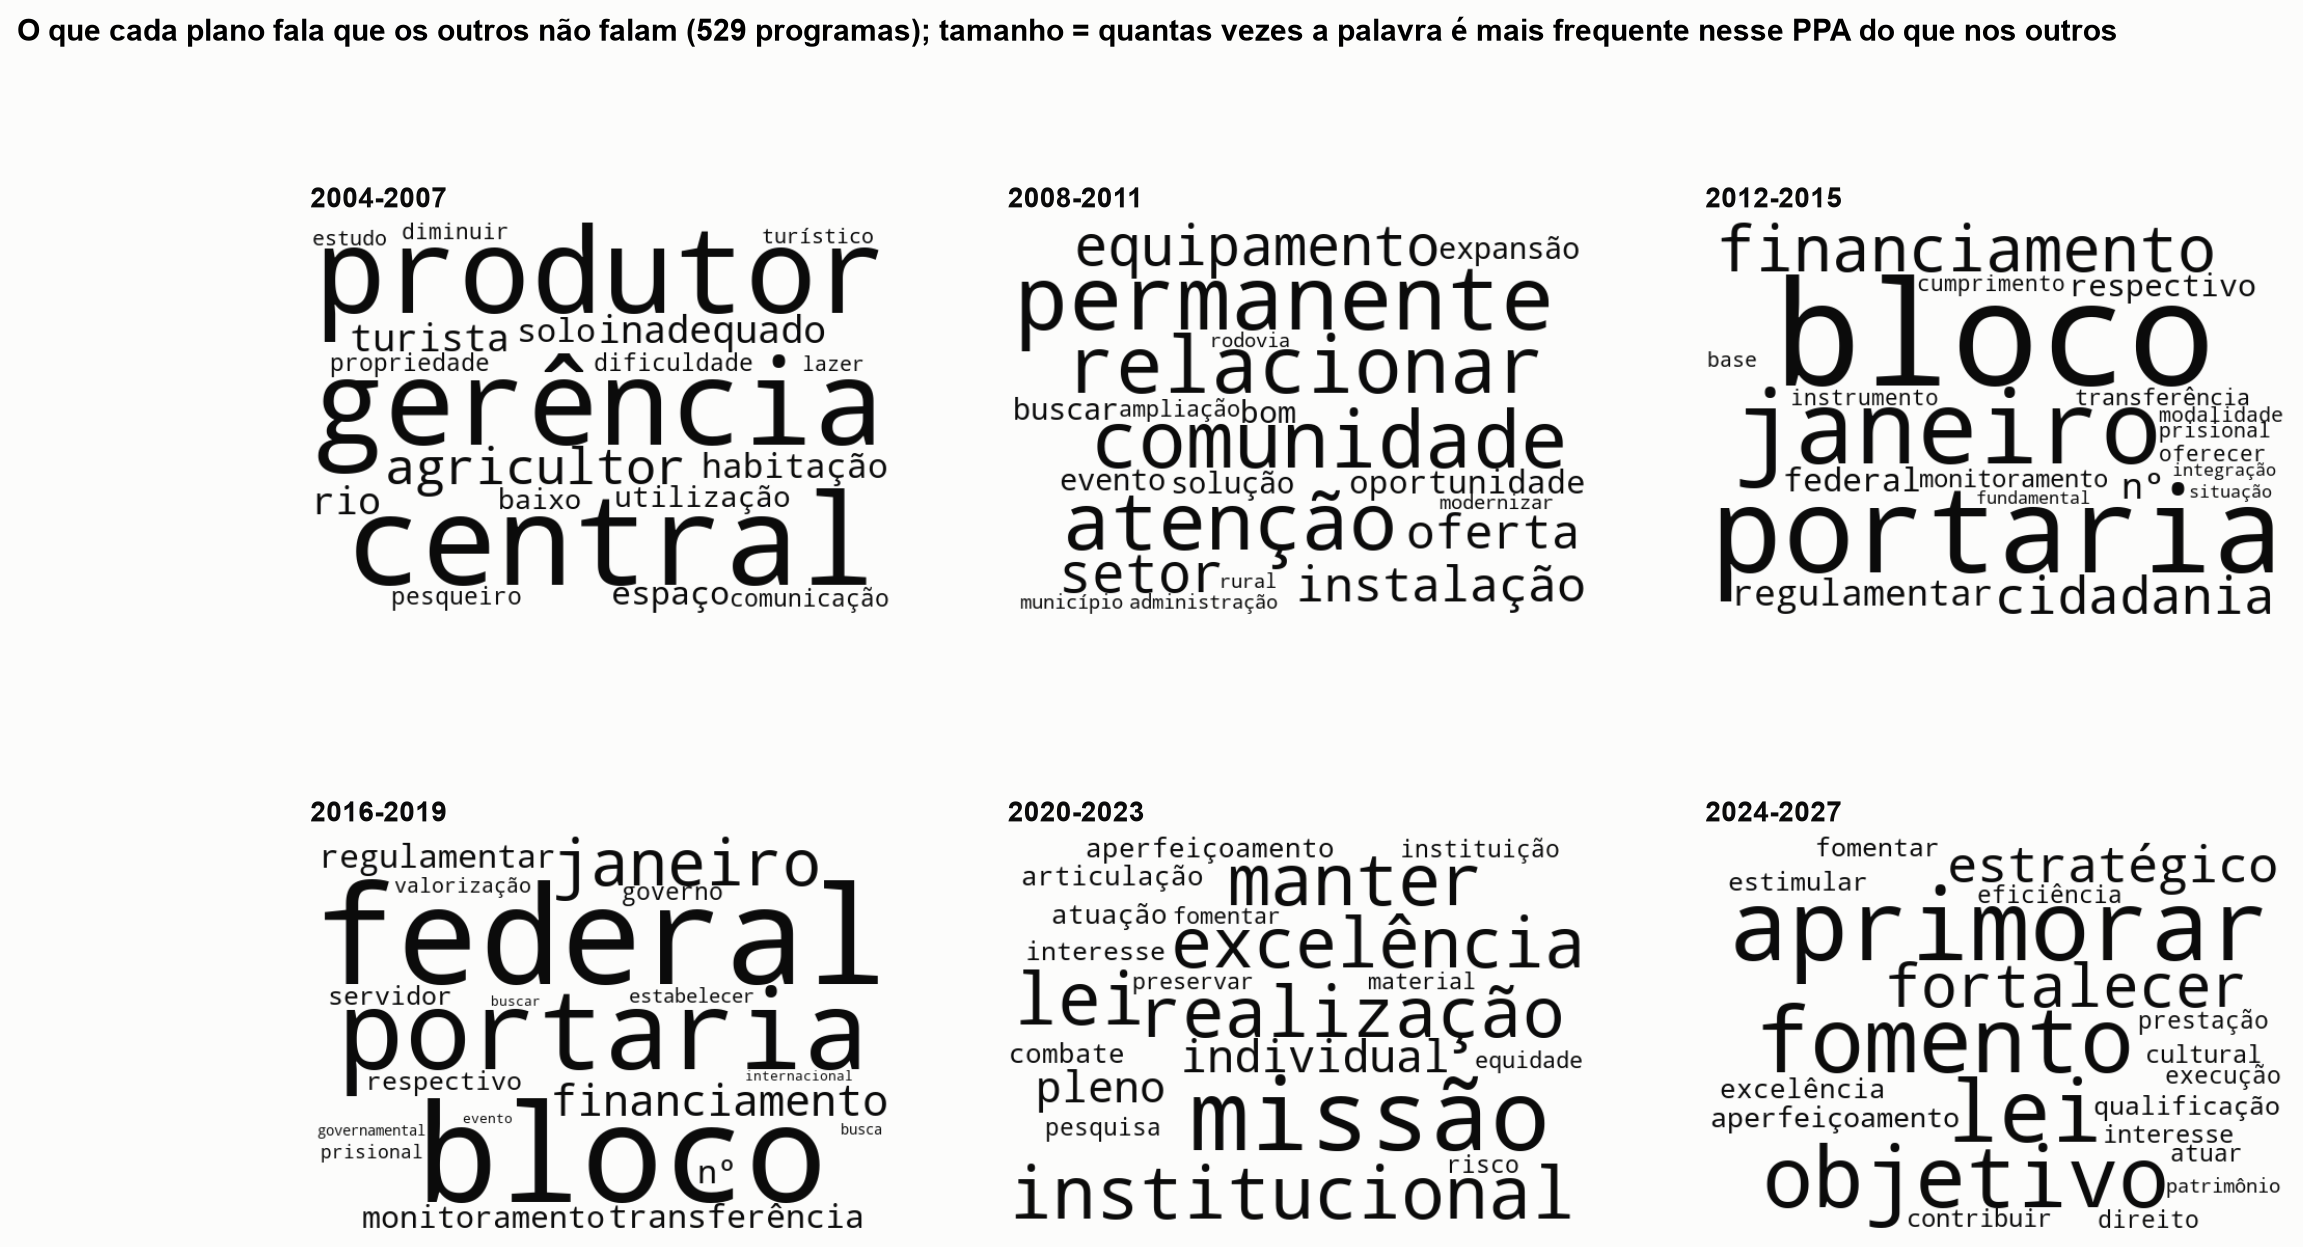

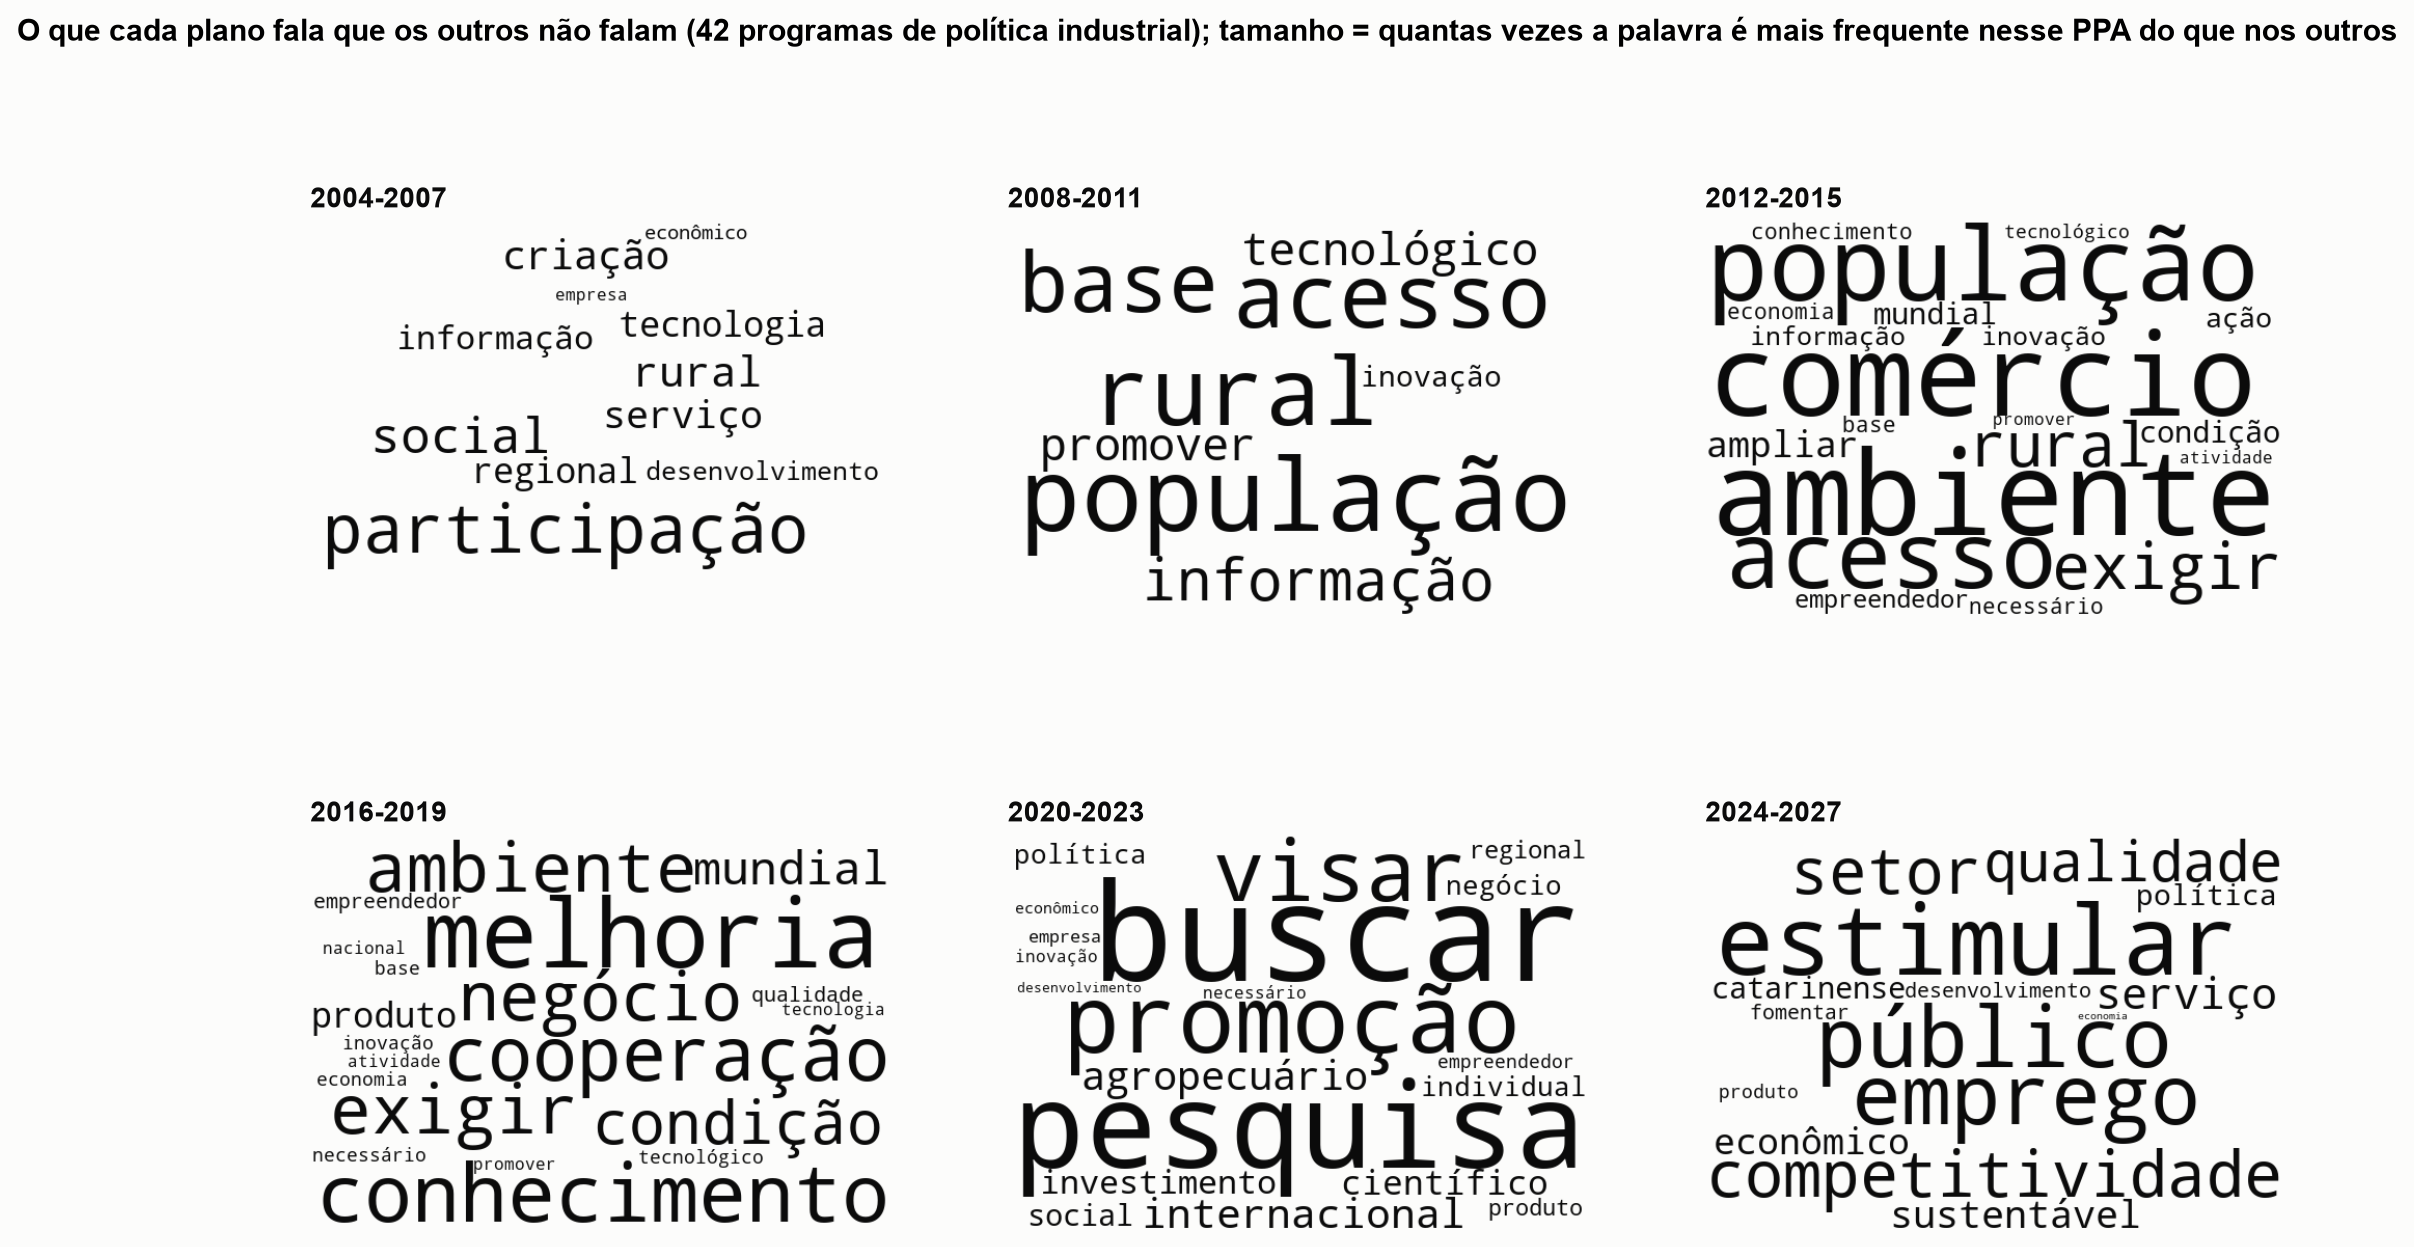

In [4]:
pc = palavras_caracteristicas(p)
fig("historia_palavras_ppa_inteiro.png", 1000)
fig("historia_palavras_selecionados.png", 1000)

As 20 palavras de cada PPA, pelas duas medidas:

In [5]:
for recorte in ("PPA inteiro", "selecionados"):
    for medida in ("contagem", "TF-IDF"):
        g = pc[(pc.recorte == recorte) & (pc.medida == medida)]
        display(Markdown(f"**{recorte}, {medida}**"))
        display(g.pivot(index="posição", columns="periodo", values="palavra").reindex(columns=PER).fillna(""))

**PPA inteiro, contagem**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,central,permanente,bloco,federal,missão,aprimorar
2,gerência,atenção,portaria,bloco,institucional,fomento
3,produtor,comunidade,janeiro,portaria,lei,lei
4,agricultor,relacionar,financiamento,janeiro,manter,objetivo
5,inadequado,equipamento,cidadania,financiamento,realização,fortalecer
6,rio,setor,regulamentar,transferência,excelência,estratégico
7,turista,instalação,nº,regulamentar,individual,aperfeiçoamento
8,habitação,oferta,federal,nº,pleno,excelência
9,espaço,oportunidade,respectivo,monitoramento,aperfeiçoamento,fomentar


**PPA inteiro, TF-IDF**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,necessidade,necessidade,necessidade,ação,público,público
2,serviço,catarinense,catarinense,promover,ação,promover
3,catarinense,desenvolvimento,qualidade,qualidade,serviço,serviço
4,ação,recurso,ação,necessidade,promover,ação
5,público,público,serviço,público,qualidade,social
6,rural,serviço,promover,recurso,catarinense,catarinense
7,recurso,condição,recurso,catarinense,gestão,desenvolvimento
8,gestão,gestão,desenvolvimento,desenvolvimento,recurso,qualidade
9,qualidade,qualidade,condição,serviço,necessidade,gestão


**selecionados, contagem**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,participação,população,ambiente,melhoria,buscar,estimular
2,social,rural,comércio,conhecimento,pesquisa,público
3,rural,acesso,população,cooperação,promoção,emprego
4,criação,base,acesso,ambiente,visar,competitividade
5,serviço,informação,exigir,exigir,internacional,setor
6,tecnologia,tecnológico,rural,negócio,agropecuário,qualidade
7,regional,promover,ampliar,condição,científico,serviço
8,informação,inovação,condição,mundial,investimento,sustentável
9,desenvolvimento,,mundial,produto,social,econômico


**selecionados, TF-IDF**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,participação,acesso,inovação,inovação,inovação,competitividade
2,social,população,tecnológico,catarinense,internacional,catarinense
3,rural,rural,acesso,tecnológico,catarinense,econômico
4,disponibilizar,tecnológico,economia,economia,empresa,desenvolvimento
5,tecnologia,propiciar,catarinense,promover,desenvolvimento,público
6,desenvolvimento,digital,promover,conhecimento,econômico,estimular
7,estimular,base,ambiente,empresa,tecnológico,qualidade
8,criação,inovação,população,condição,promover,definir
9,informação,informação,empresa,produto,pesquisa,qualificação


**Leitura:** no plano inteiro, as palavras características são quase todas de formato: a estrutura de gerências regionais em 2004-2007, as portarias e os blocos de financiamento da saúde em 2012-2019, "missão" e "institucional" em 2020-2023. O conteúdo aparece em 2004-2007, com **produtor, agricultor e pesqueiro**. O TF-IDF no plano inteiro devolve só palavras que todos os planos usam (necessidade, serviço, público); por isso a contagem relativa é a medida da história.

Na política industrial a sequência é nítida: **participação, social e rural** (2004-2007); **população, acesso, rural, base tecnológica e informação** (2008-2011); **comércio, ambiente de inovação, conhecimento, empreendedor e negócio** (2012-2019); **pesquisa, promoção, internacional e científico** (2020-2023); **competitividade, emprego, setor, estimular e público** (2024-2027). O TF-IDF de 20 palavras dos selecionados reproduz a primeira versão.

## 2. O agro sai de cena

Tema agro (lista estrita aprovada em 19/11/2026): rural, agropecuário, agricultura, agrícola, agricultor, pesqueiro, pescador, pesca, aquicultor, aquicultura, produtor, leite, pecuária, agronegócio, florestal. Três medidas no plano inteiro: discurso (% dos lemas), estrutura (% dos programas da área de agricultura e pesca) e orçamento (% do valor sem pessoal e emendas).

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_temas.png


figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_agro.png


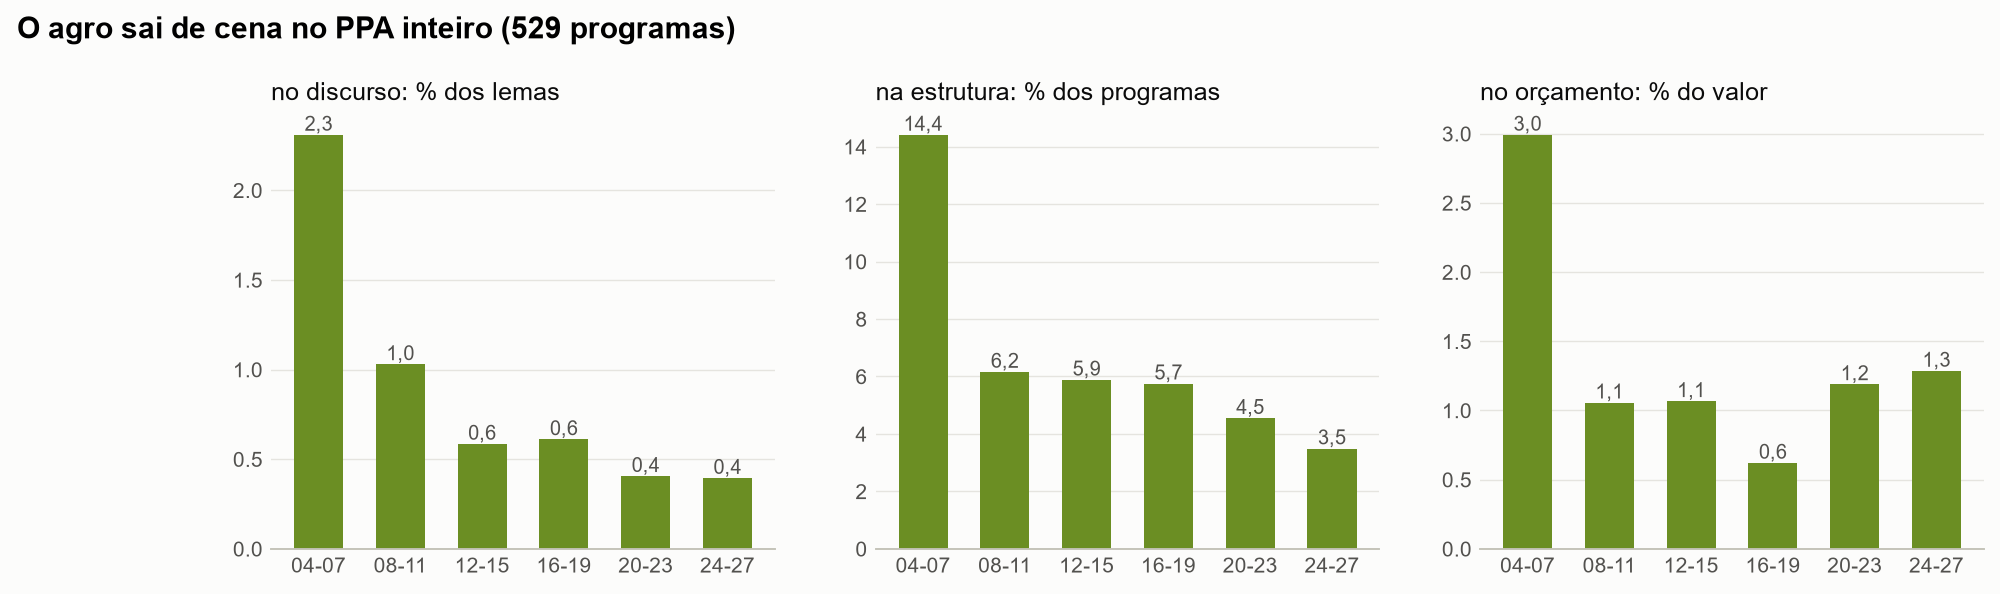

PPA,% dos lemas (tema agro),ocorrências de 'rural',% dos programas (área agricultura e pesca),programas da área,% do valor do PPA (sem pessoal e emendas)
2004-2007,"2,31",28,"14,41",17,"2,99"
2008-2011,"1,03",11,"6,15",4,"1,06"
2012-2015,"0,58",7,"5,88",5,"1,07"
2016-2019,"0,61",7,"5,75",5,"0,62"
2020-2023,"0,40",3,"4,55",4,"1,19"
2024-2027,"0,39",2,"3,49",3,"1,29"


In [6]:
temas = temas_no_tempo(p)
tab_agro = agro(p, s, temas)
fig("historia_agro.png", 1000)
tabela(tab_agro, 2)

**Leitura:** no plano inteiro, o vocabulário agro cai de **2,3% dos lemas em 2004-2007 para 0,4% em 2024-2027** ("rural": de 28 ocorrências para 2), e a queda passa nos testes (p = 0,004 na variação e 0,015 na tendência, 3.000 permutações). É o único tema que muda de forma significativa no plano inteiro. A estrutura acompanha: a área de agricultura e pesca tinha 17 programas (14% do plano) em 2004-2007 e tem 3 (3,5%) em 2024-2027. No orçamento, a parcela cai até 2016-2019 (de 3,0% para 0,6%) e se recupera em parte depois (1,3%). Ressalva: o 2004-2007 tinha 118 programas, mais fragmentados, então parte da queda no número de programas é consolidação.

## 3. Da inovação à competitividade

% dos lemas de cada tema por PPA, no plano inteiro e na política industrial. Temas: agro e as dimensões do léxico validado. "p variação" e "p tendência": permutação do PPA de cada programa (3.000 sorteios).

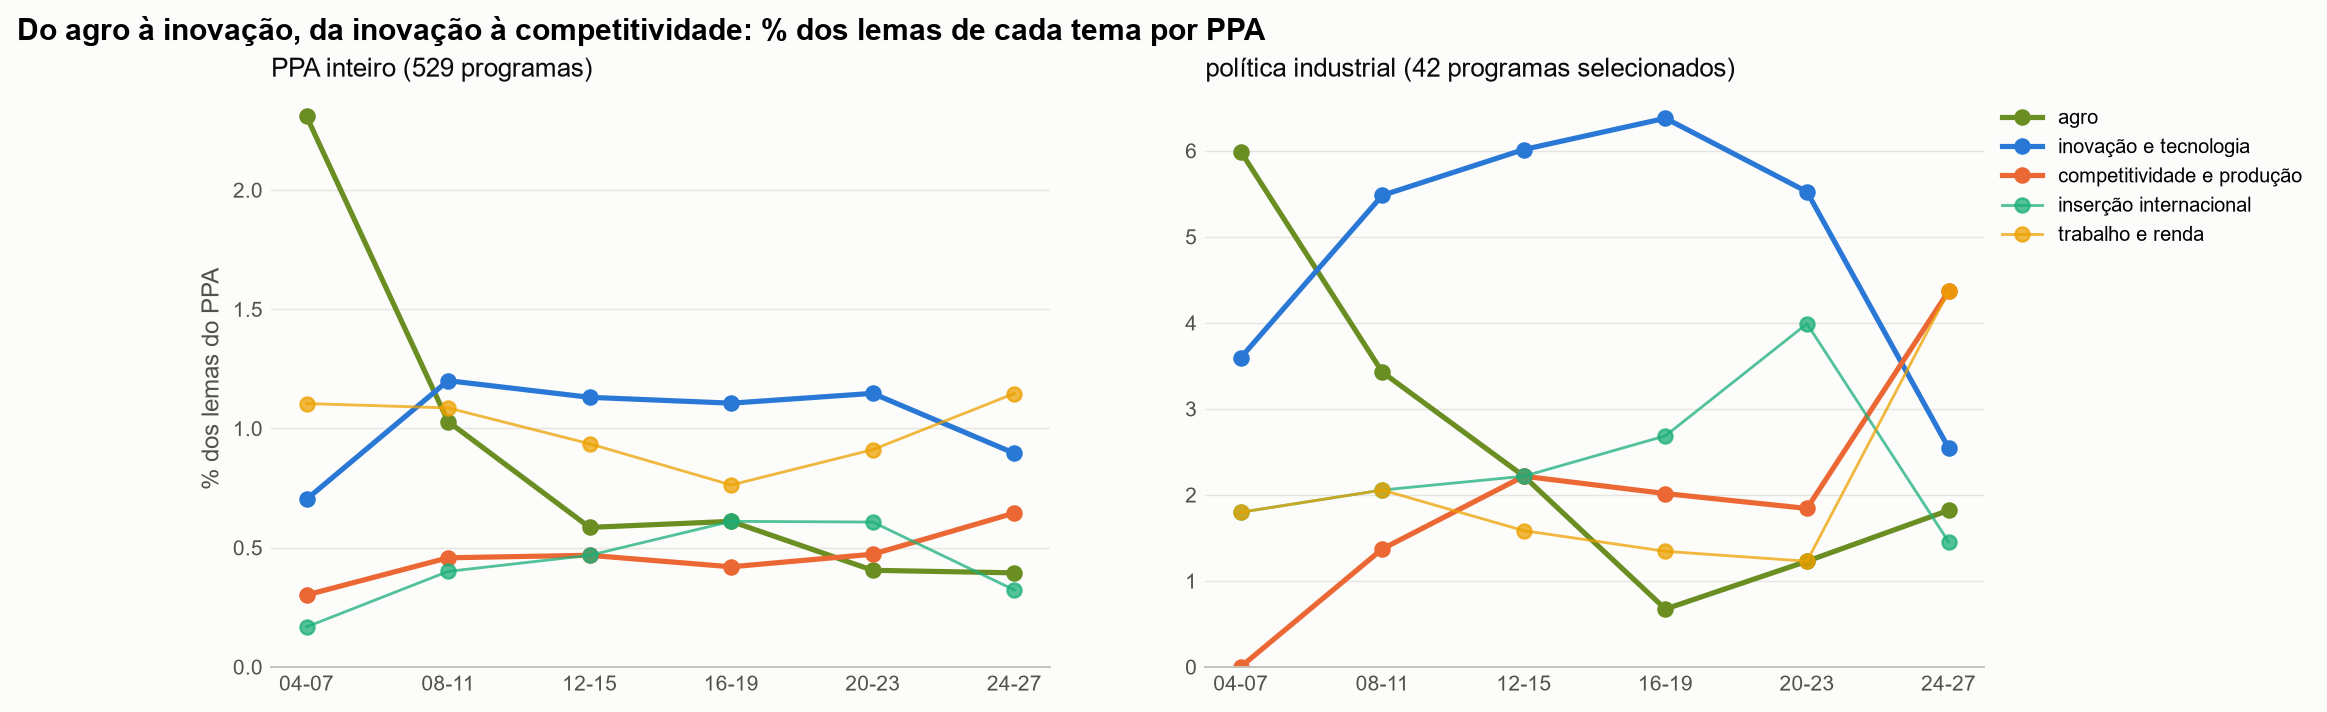

recorte,tema,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027,p variação,p tendência
PPA inteiro,agro,"2,31","1,03","0,58","0,61","0,40","0,39","0,004","0,015"
PPA inteiro,inovação e tecnologia,"0,70","1,20","1,13","1,11","1,15","0,90","0,922","1,000"
PPA inteiro,competitividade e produção,"0,30","0,46","0,47","0,42","0,47","0,64","0,677","0,053"
PPA inteiro,inserção internacional,"0,17","0,40","0,47","0,61","0,61","0,32","0,619","0,485"
PPA inteiro,trabalho e renda,"1,10","1,09","0,94","0,76","0,91","1,15","0,941","0,920"
selecionados,agro,"5,99","3,42","2,22","0,67","1,23","1,82","0,741","0,091"
selecionados,inovação e tecnologia,"3,59","5,48","6,01","6,38","5,52","2,55","0,932","1,000"
selecionados,competitividade e produção,"0,00","1,37","2,22","2,01","1,84","4,36","0,004","0,098"
selecionados,inserção internacional,"1,80","2,05","2,22","2,68","3,99","1,45","0,851","0,806"
selecionados,trabalho e renda,"1,80","2,05","1,58","1,34","1,23","4,36","0,821","0,927"


Ocorrências por PPA:

recorte,tema,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,agro,69,18,15,16,12,11
PPA inteiro,inovação e tecnologia,21,21,29,29,34,25
PPA inteiro,competitividade e produção,9,8,12,11,14,18
PPA inteiro,inserção internacional,5,7,12,16,18,9
PPA inteiro,trabalho e renda,33,19,24,20,27,32
selecionados,agro,10,5,7,2,4,5
selecionados,inovação e tecnologia,6,8,19,19,18,7
selecionados,competitividade e produção,0,2,7,6,6,12
selecionados,inserção internacional,3,3,7,8,13,4
selecionados,trabalho e renda,3,3,5,4,4,12


In [7]:
fig("historia_temas.png", 1050)
tabela(temas[["recorte", "tema"] + PER + ["p variação", "p tendência"]], 2)
display(Markdown("Ocorrências por PPA:"))
tabela(temas[["recorte", "tema"] + [f"{q} n" for q in PER]].rename(columns=lambda c: c.replace(" n", "")), 0)

**Leitura:** na política industrial, **inovação e tecnologia** sobem de 3,6% dos lemas em 2004-2007 para 6,4% em 2016-2019 e caem para 2,5% em 2024-2027. **Competitividade e produção**, que não existe em 2004-2007, fica perto de 2% de 2012 a 2023 e salta para **4,4% em 2024-2027**: é o único tema da política industrial que varia além do acaso (p = 0,004). Trabalho e renda também sobe em 2024-2027 (4,4%, puxado pelo 0354) e inserção internacional tem seu pico em 2020-2023 (4,0%, pelo 0212). A queda da inovação em 2024-2027, sozinha, não passa no teste. No plano inteiro as curvas são quase planas, com exceção do agro: **a mudança de discurso é da política industrial, não do Estado como um todo.** Contagens pequenas: na política industrial, cada tema tem de 0 a 19 ocorrências por PPA.

## 4. A inovação sai da política industrial

De onde vem o vocabulário de inovação do plano (inovação, tecnologia, modernização, tecnológico): dos programas de política industrial ou dos demais?

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_quem_fala_inovacao.png


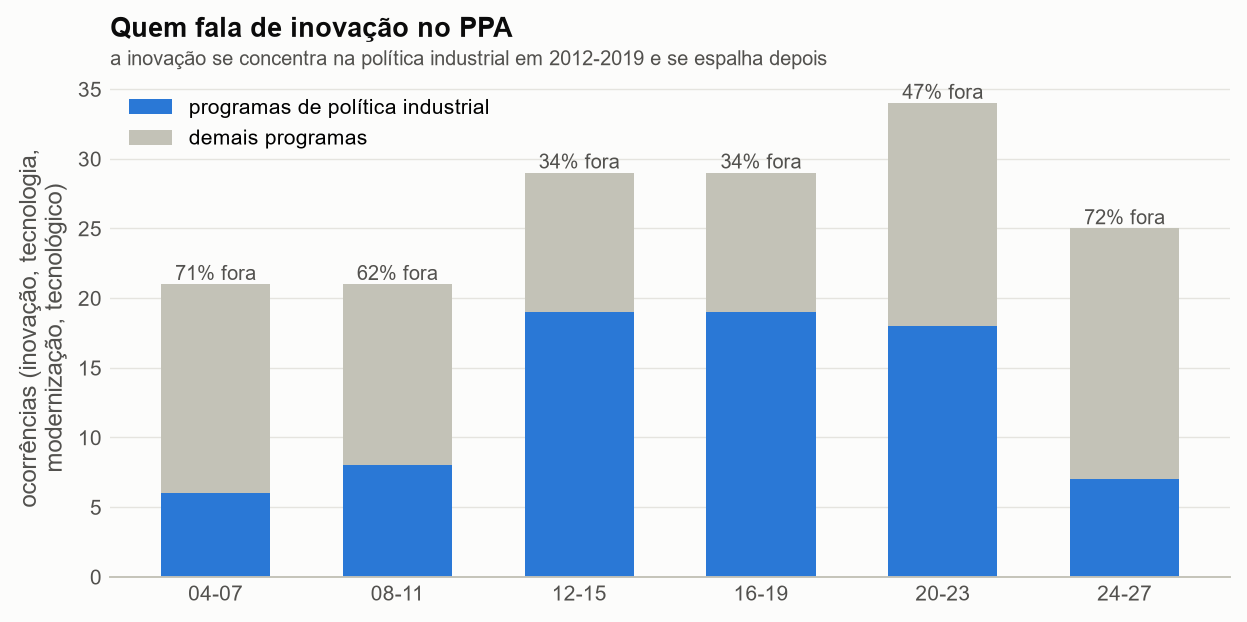

PPA,ocorrências nos selecionados,ocorrências nos demais programas,% fora da política industrial
2004-2007,6,15,"71,4"
2008-2011,8,13,"61,9"
2012-2015,19,10,"34,5"
2016-2019,19,10,"34,5"
2020-2023,18,16,"47,1"
2024-2027,7,18,"72,0"


PPA,programas de fora que mais usam o vocabulário de inovação
2004-2007,0226 Leite e Carne em Pastagem Melhorada (3); 0502 Gestão da Tecnologia da Informação e Comunica (2); 0600 Apoio Administrativo - Celesc (2); 0170 Modernização da Gestão de Materiais e Serviço (1)
2008-2011,0430 Descentralização da Média e Alta Complexidade (2); 0840 PNAGE - Programa Nacional de Apoio à Moderniz (2); 0905 Gestão Administrativa - Celesc (2); 0220 Governança Eletrônica (1)
2012-2015,0220 Governança Eletrônica (2); 0840 PNAGE - Programa Nacional de Apoio à Moderniz (2); 0830 Modernização da Administração Fazendária (1); 0145 Elaboração de Projetos e Estudos de Infraestr (1)
2016-2019,0220 Governança Eletrônica (2); 0830 Modernização da Administração Fazendária (1); 0145 Elaboração de Projetos e Estudos de Infraestr (1); 0250 Inclusão Digital (1)
2020-2023,0430 Atenção de Média e Alta Complexidade Ambulato (3); 0701 Redução da Criminalidade (2); 0704 Melhoria Estrutural da Segurança Pública (2); 0115 Gestão do Sistema de Transporte Intermunicipa (1)
2024-2027,0701 Redução da Criminalidade (2); 0704 Melhoria Estrutural da Segurança Pública (2); 0770 DETRAN Digital (2); 0430 Atenção Especializada à Saúde (2)


In [8]:
qf, quem = quem_fala_de_inovacao(p)
fig("historia_quem_fala_inovacao.png", 800)
tabela(qf, 1)
with pd.option_context("display.max_colwidth", None):
    display(quem.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

**Leitura:** em 2012-2019, dois terços do vocabulário de inovação do plano estavam na política industrial. Em 2024-2027, **72% estão fora dela**: segurança pública (0701 Redução da Criminalidade, 0704), DETRAN Digital, saúde. A inovação deixa de ser palavra da política produtiva e vira palavra de modernização do Estado. Os outros resultados apontam na mesma direção: em 2024-2027 "inovação" aparece na mesma frase que "público" e "serviço", e nas subações dos selecionados surge "inovação na gestão pública" já em 2020-2023.

## 5. Competitividade: com quem ela anda

Os 10 lemas mais próximos de competitividade e de inovação nas duas metades do período (proximidade = frases em comum, ver `redes_ppa.ipynb`).

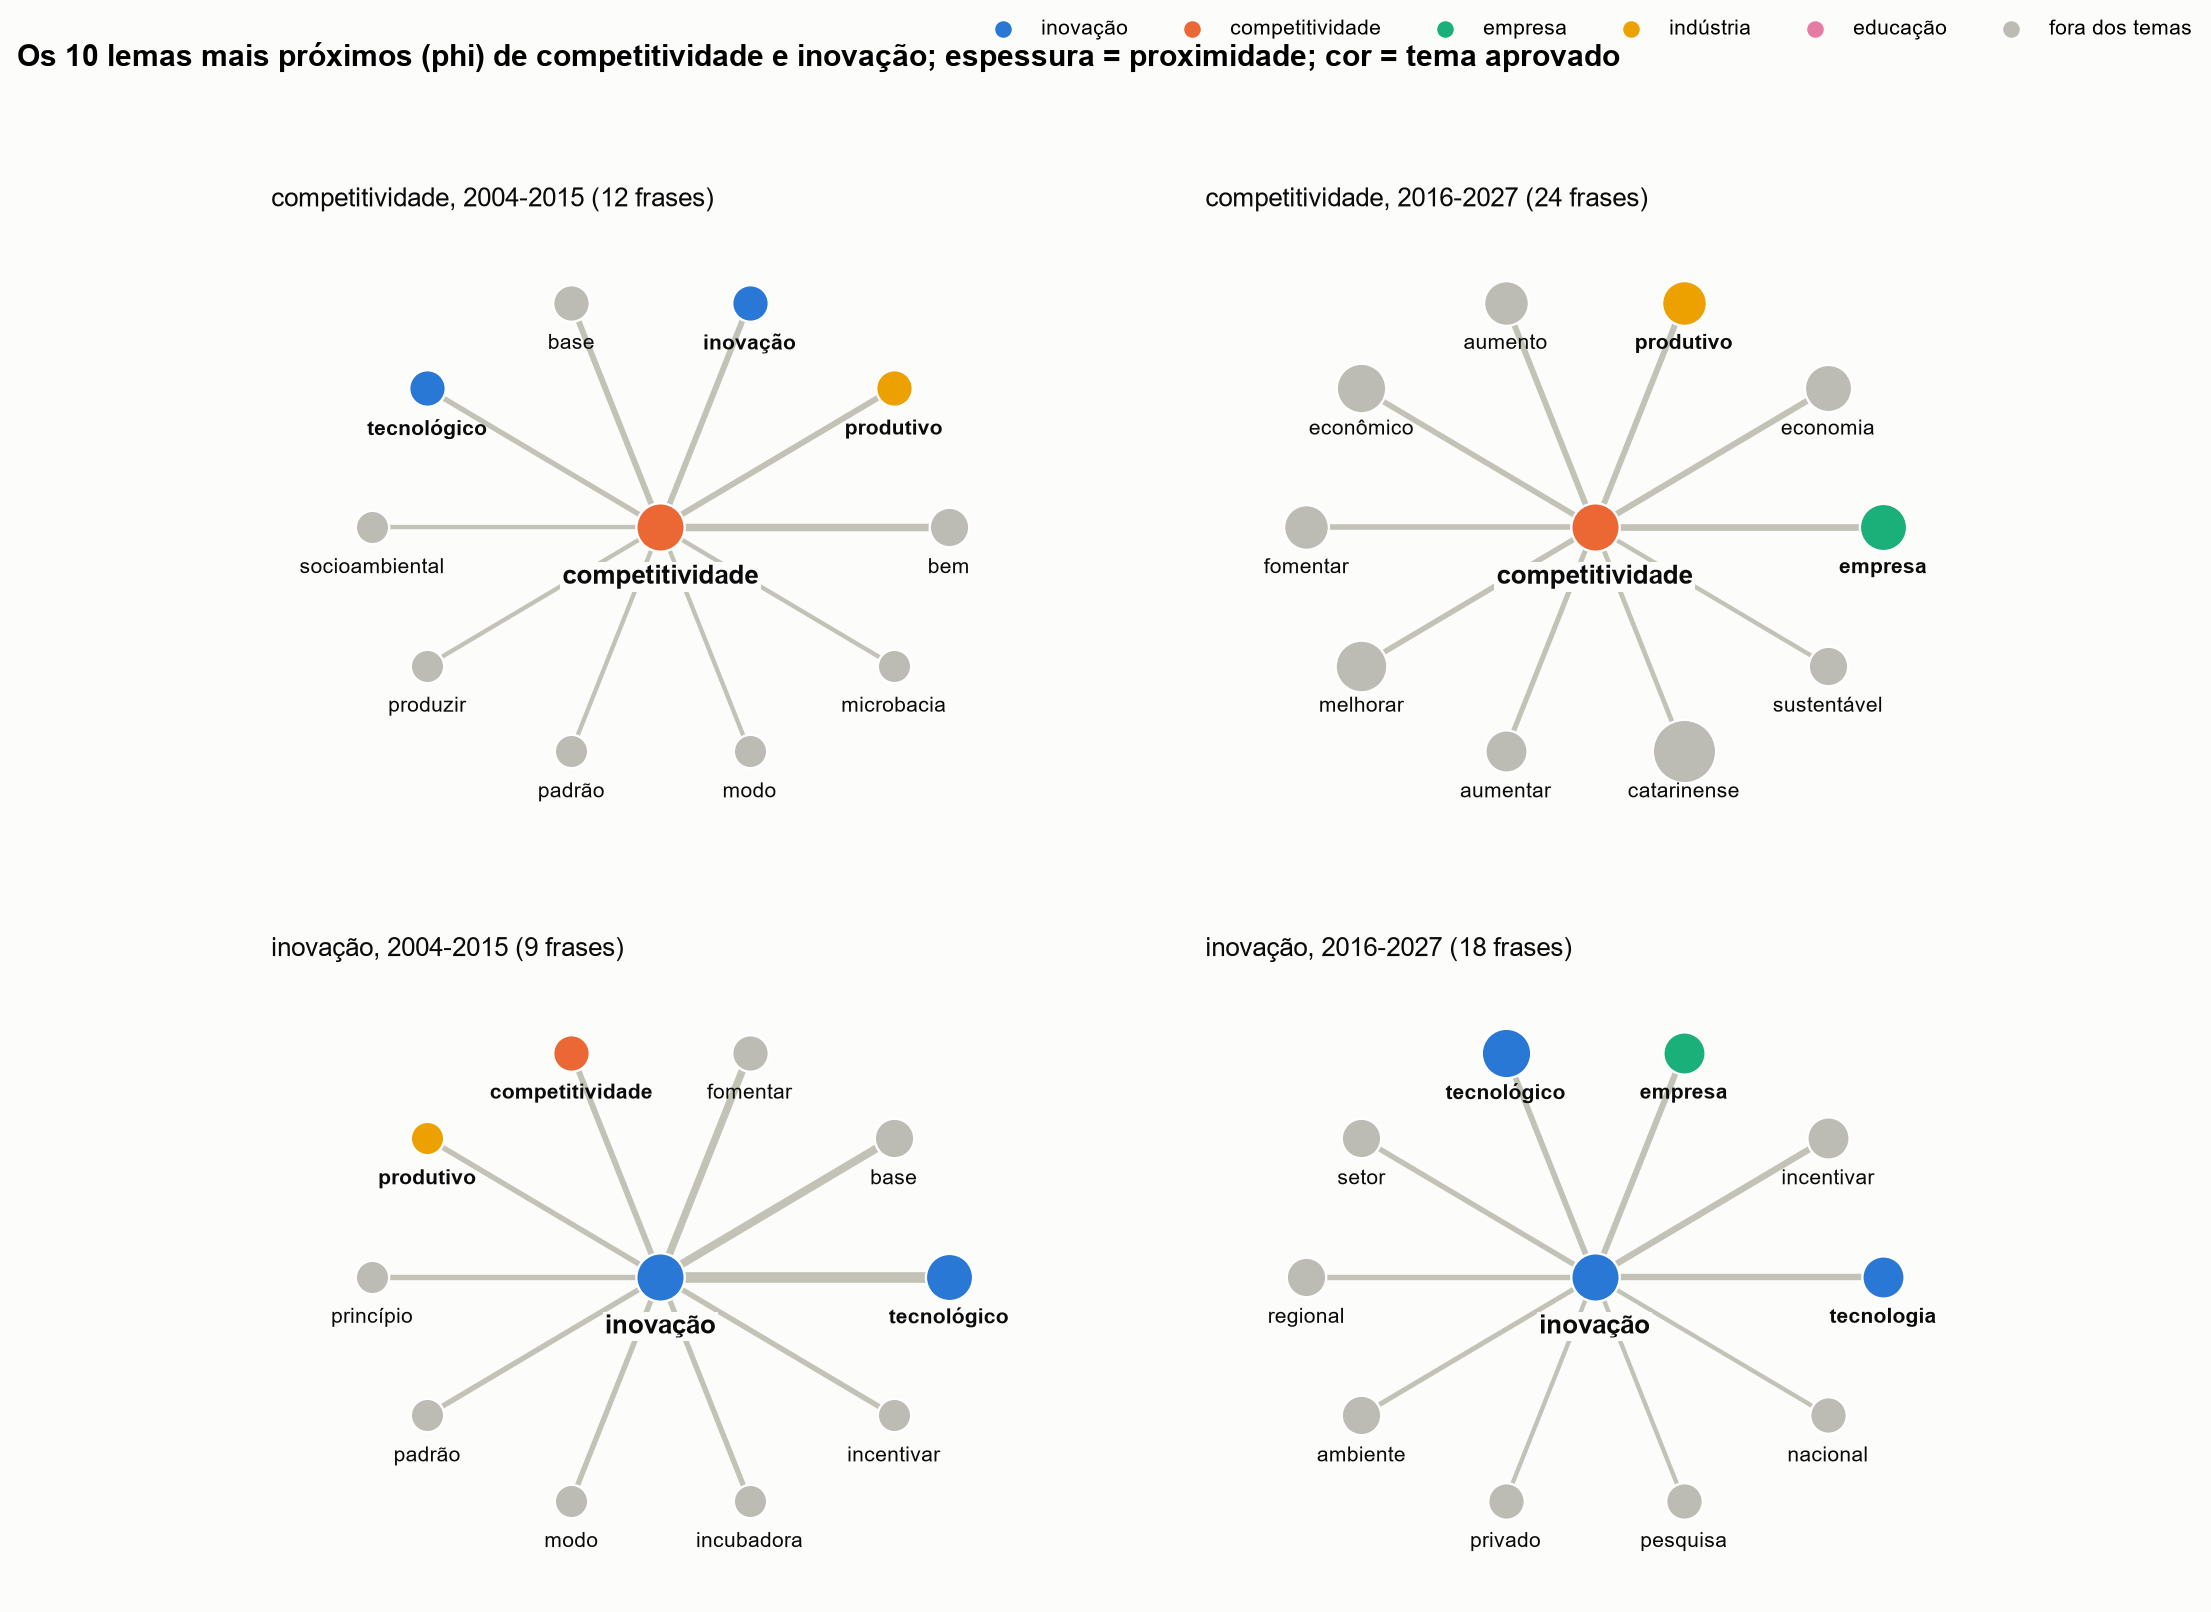

In [9]:
fig("rede_termos_vizinhancas.png", 900)

**Leitura:** em 2004-2015, competitividade aparece com **produtivo, inovação, base e tecnológico**; em 2016-2027, com **empresa, economia, aumento e econômico**, e inovação sai da vizinhança. A alta de competitividade está no texto novo: contando só as frases reescritas, ela vai de 1,8% para 5,3% dos lemas da política industrial em 2024-2027.

## 6. O discurso sobe, o dinheiro desce

À esquerda, o que a política industrial diz (% dos lemas). À direita, o que o orçamento faz (% do valor do próprio PPA). Valores orçados e nominais; 2004-2007 e 2008-2011 trazem um ano só, por isso tudo em % do PPA.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_discurso_orcamento.png


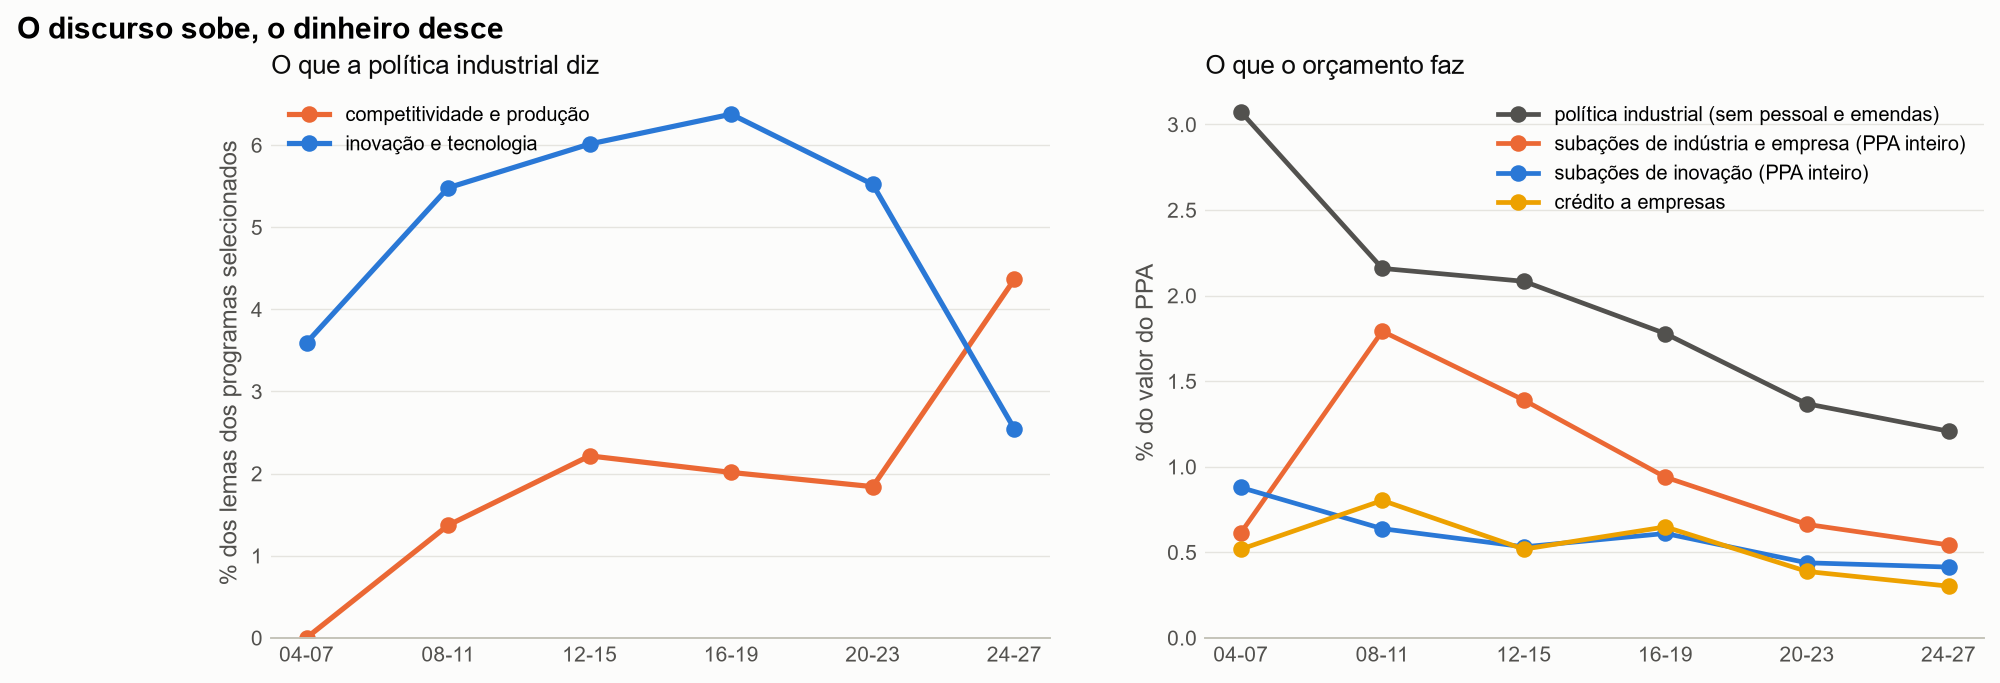

PPA,"competitividade e produção (% lemas, selecionados)","inovação e tecnologia (% lemas, selecionados)",política industrial (sem pessoal e emendas) (% PPA),subações de indústria e empresa (PPA inteiro) (% PPA),subações de inovação (PPA inteiro) (% PPA),crédito a empresas (% PPA)
2004-2007,"0,00","3,59","3,07","0,61","0,88","0,52"
2008-2011,"1,37","5,48","2,16","1,79","0,64","0,80"
2012-2015,"2,22","6,01","2,08","1,39","0,53","0,52"
2016-2019,"2,01","6,38","1,78","0,94","0,61","0,65"
2020-2023,"1,84","5,52","1,37","0,66","0,44","0,39"
2024-2027,"4,36","2,55","1,21","0,54","0,41","0,30"


In [10]:
tab_do = discurso_orcamento(temas)
fig("historia_discurso_orcamento.png", 1000)
tabela(tab_do, 2)

**Leitura:** a parcela da política industrial no orçamento (sem pessoal e emendas) **cai em todos os planos**, de 3,1% para 1,2% do PPA. O crédito a empresas vai de 0,8% (2008-2011) para 0,3%, e as subações de inovação e de indústria e empresa do plano inteiro também perdem peso (0,41% e 0,54% em 2024-2027). Em 2024-2027, o público declarado que mais recebe da política industrial é **município, não empresa** (0,67% contra 0,42% do PPA), pelo 0200, cujo público passa a ser "Municípios atendidos".

## 7. Planos copiados, política reescrita

% dos lemas em frases iguais ou quase iguais (similaridade de 0,9 ou mais) às do PPA anterior. Tipo de transição (reeleição ou troca de governador): [verificar].

figura:

 C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_copia.png


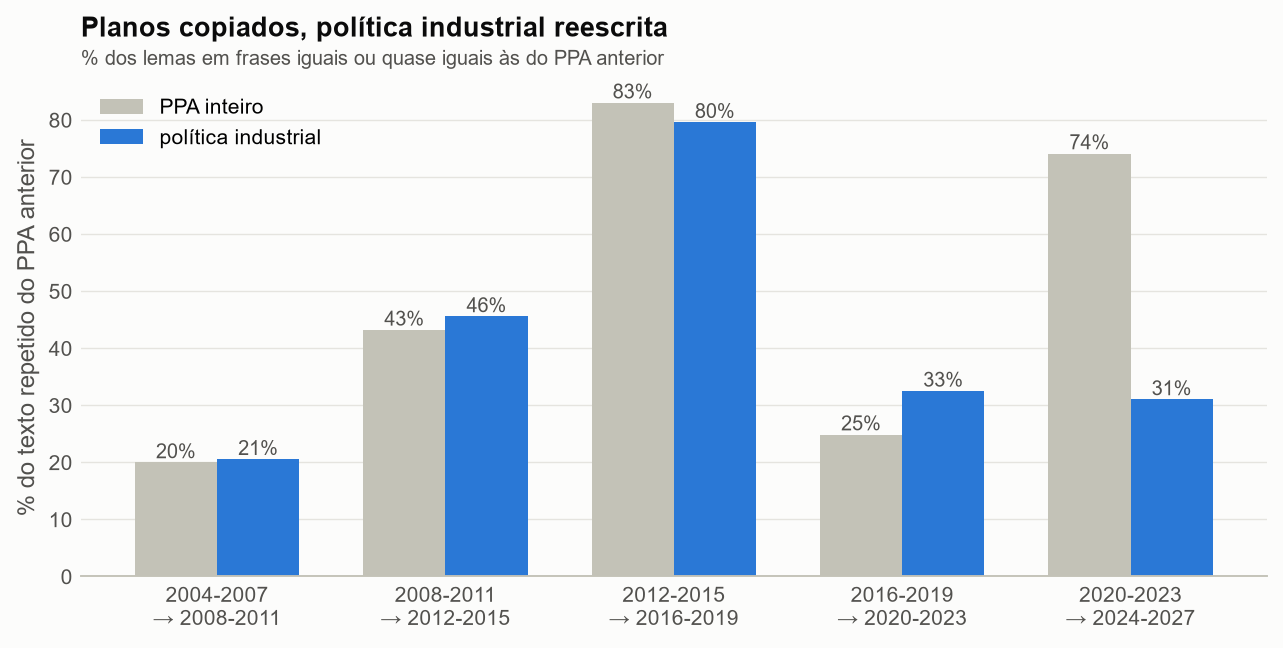

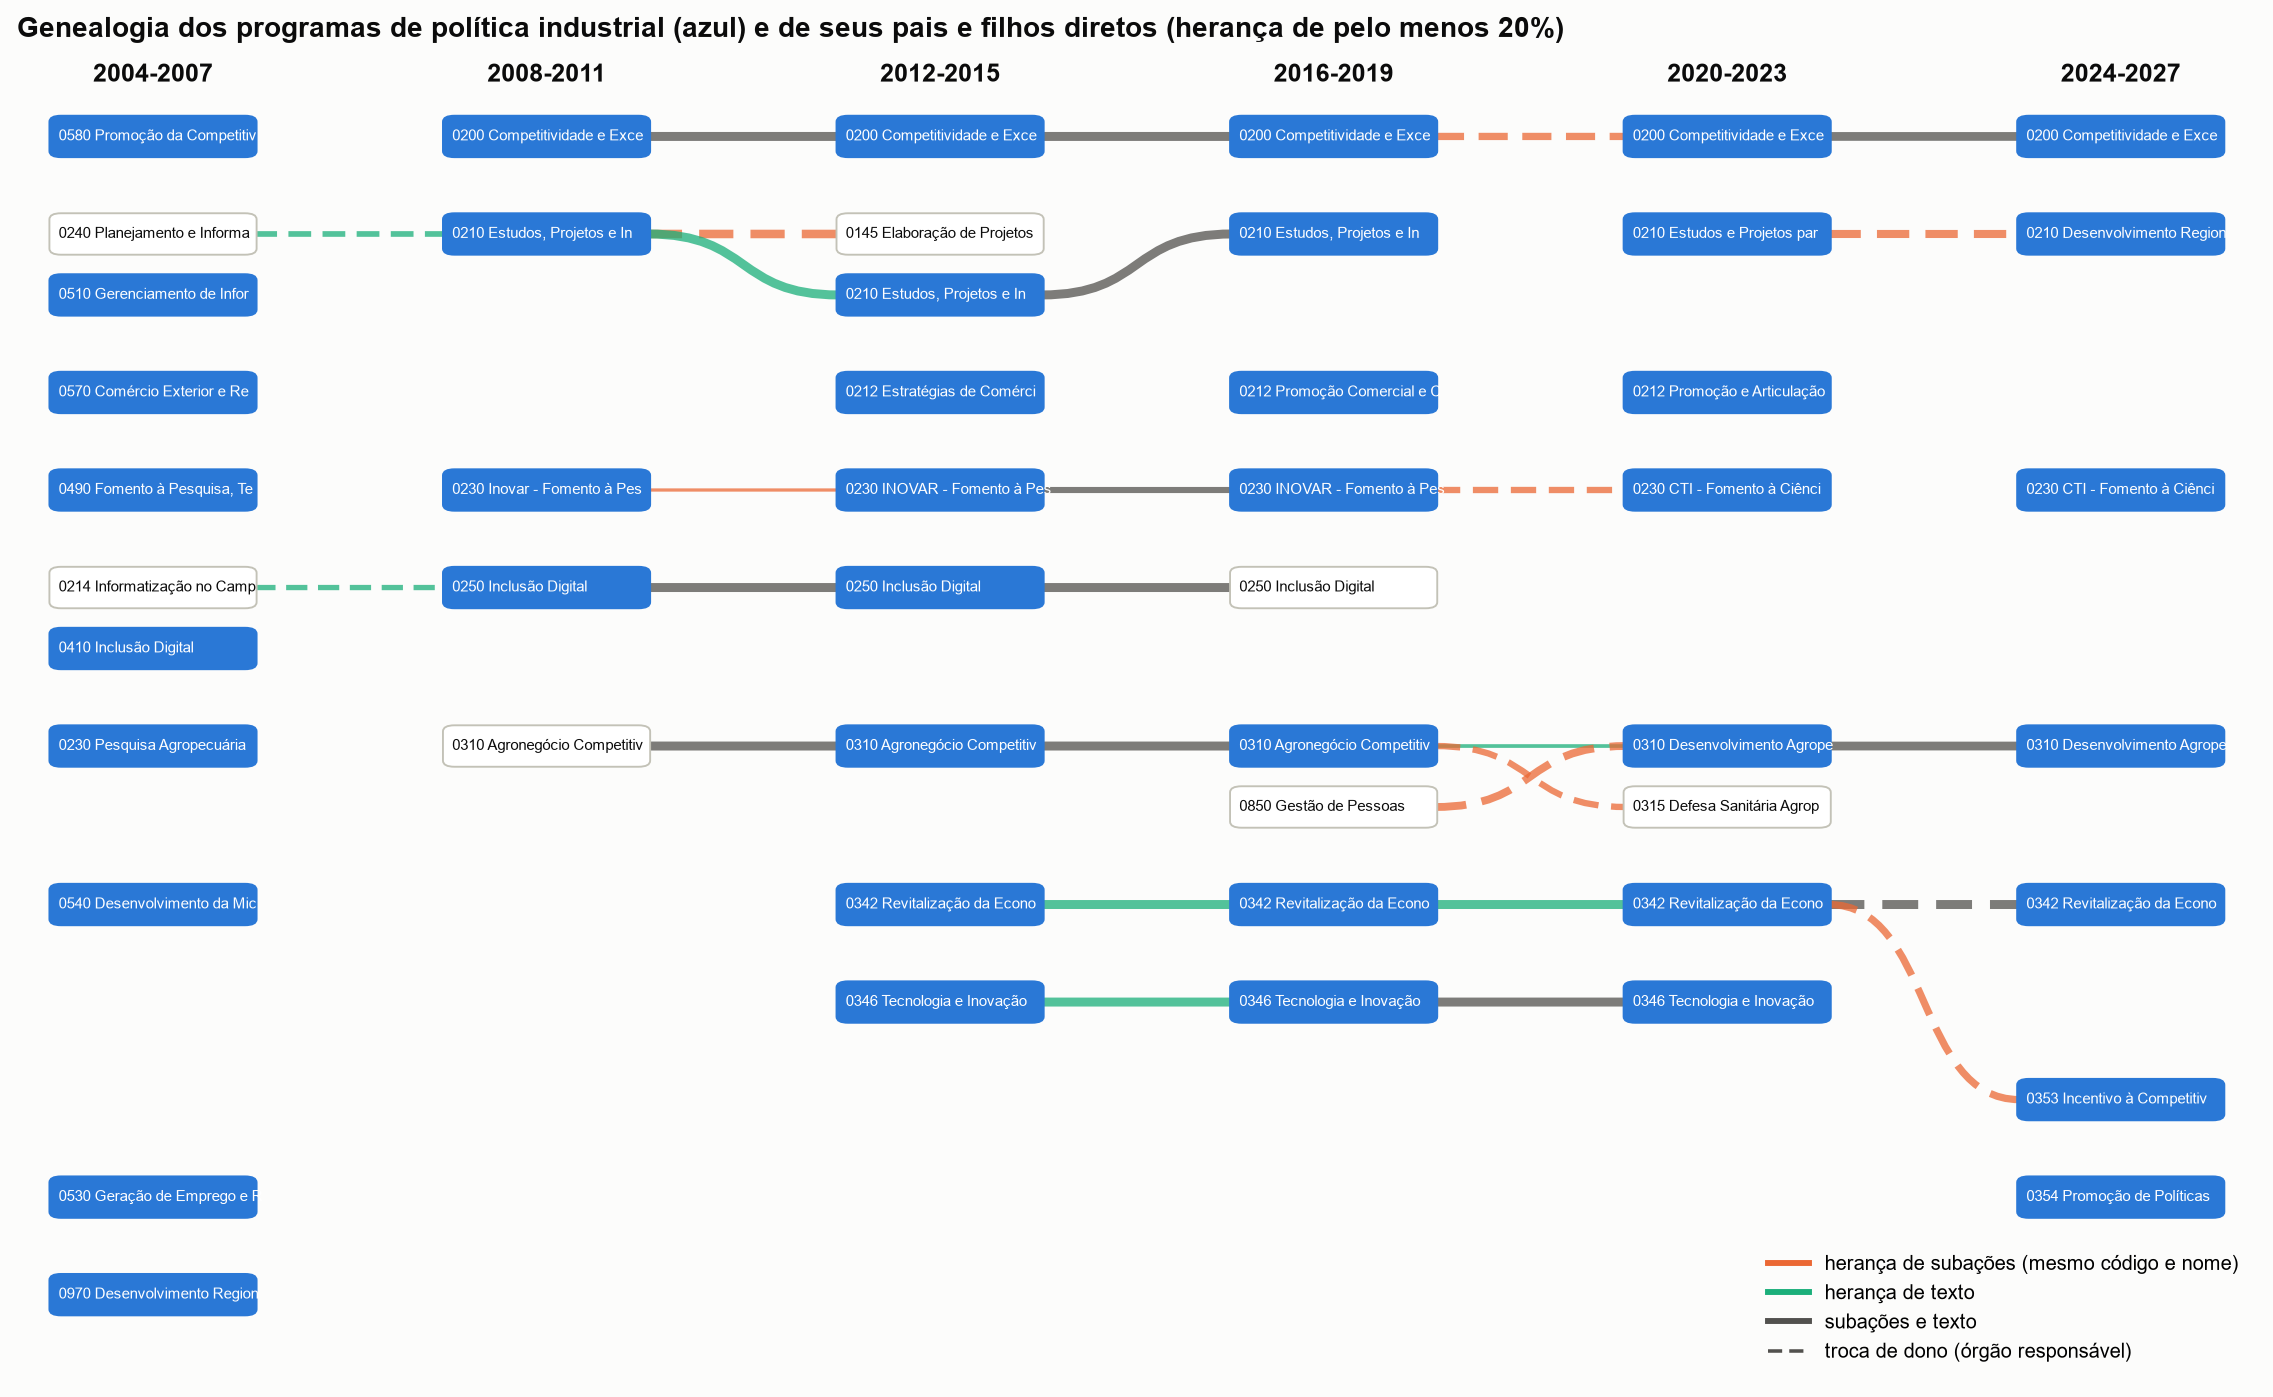

In [11]:
tab_copia = copia()
fig("historia_copia.png", 850)
fig("rede_genealogia.png", 1100)

**Leitura:** a reeleição de 2015 [verificar] copia 83% do texto; a troca de 2019 [verificar], só 25%, junto com um formato novo de plano. Em 2024-2027, o plano repete **74%** do anterior, mas a política industrial só **31%**: o 0342 e o novo 0353 passam para a Secretaria da Indústria, do Comércio e do Serviço, o 0230 para a de Ciência, Tecnologia e Inovação [verificar datas de criação], e o 0353 nasce de uma divisão do 0342 (77% do valor das subações vem dele). A genealogia acima mostra a linhagem de cada programa de política industrial.

## 8. Os planos se parecem?

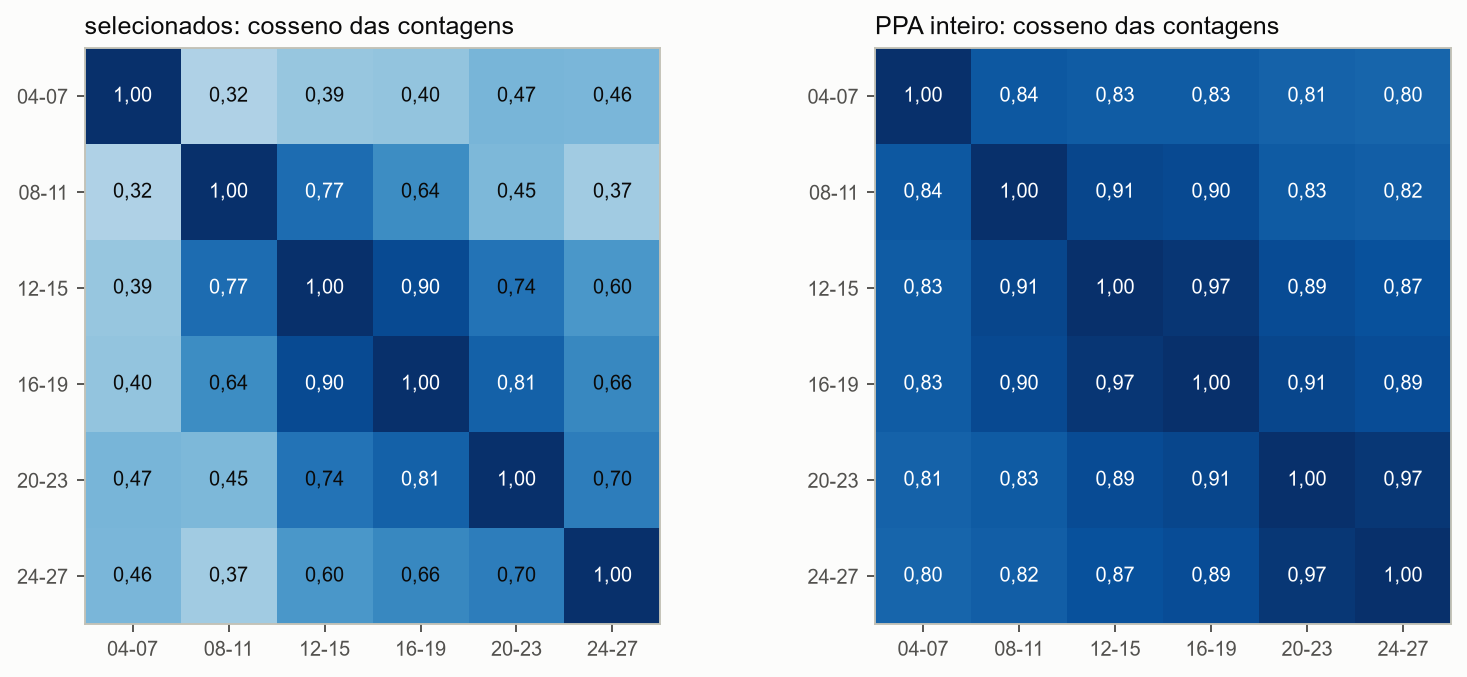

In [12]:
fig("contagem_similaridade_entre_ppas.png", 900)

**Leitura:** na política industrial, planos vizinhos são parecidos (0,70 a 0,90) e o 2004-2007 fica isolado (0,32 a 0,47), como na primeira versão com TF-IDF. No plano inteiro todos se parecem (0,80 a 0,97), e 2020-2023 e 2024-2027 são quase iguais (0,97), coerente com a cópia de 74%.

## O que essa história permite dizer, e o que não permite

**Permite:** descrever a mudança do discurso da política industrial (do agro e do acesso à inovação, da inovação à competitividade), mostrar que o agro perde espaço no plano inteiro, e mostrar que o discurso de política industrial se descola do orçamento.

**Não permite:** dizer que a política foi executada (o PPA é intenção e orçamento planejado), atribuir as mudanças a governos sem conferir datas e fatos ([verificar]), nem tratar as contagens da política industrial como grandes (dezenas de ocorrências por PPA, no máximo).

**Para fechar a narrativa:** ligar cada capítulo ao contexto (política industrial federal de cada período, ciclo de commodities, criação das secretarias estaduais), todo marcado [verificar] em `docs/contexto-historico.md`.